# RetailPulse — Step 4: Churn Prediction (without leakage)

**Goal:** predict which customers will cut their spending next quarter, measure accuracy honestly, explain what drives it, and score today's customers.

**Churn definition.** No customer in this data ever stops buying (Step 1), so churn means a **drop in spend**:

> churn = 1 if a customer's spend next quarter, at list price, is **more than 30% below** their spend in the same quarter last year.

Comparing with the *same quarter last year* removes seasonality (Step 2). Why *list price* is explained in section 1.

**No leakage: a time split.** For each cutoff date, features use only sales **before** the cutoff and the label comes from the 3 months **after** it.
Models are trained on earlier cutoffs and tested on a later quarter they have never seen.
The code is in `src/churn.py` (it reuses `customer_features` from Step 2).

## 0. Setup

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd, joblib, shap
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             confusion_matrix, precision_score, recall_score)
from xgboost import XGBClassifier

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.cleaning import connect
from src.churn import churn_table, CHURN_FEATURES, DROP_RATIO

PROC, MODELS = ROOT / 'data' / 'processed', ROOT / 'models'
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.3f}'.format); pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'

con = connect(ROOT / 'retail_clean_dataset', PROC / 'sales_clean.parquet')

## 1. Build the churn dataset (one row per customer per cutoff)
Cutoffs are the first day of each quarter from January 2023 (one full year of history is needed for "same quarter last year") to October 2025
(the last quarter with a known outcome). That gives 12 cutoffs × 10,000 customers.

In [2]:
cutoffs = pd.date_range('2023-01-01', '2025-10-01', freq='QS')
t = time.time()
data = pd.concat([churn_table(con, c) for c in cutoffs])
print(f'{len(data):,} rows from {len(cutoffs)} cutoffs in {time.time() - t:.0f}s')

120,000 rows from 12 cutoffs in 71s


**Why list price?** A first version measured spend *after* discounts. Its churn rate swung between 7% and 29% from quarter to quarter,
following the promotion calendar: when the next quarter had big store-wide discounts and the same quarter last year did not, customers "churned"
simply because they paid less for the same items. Measuring spend at list price (quantity × price) removes that effect, so the label reflects buying behaviour.

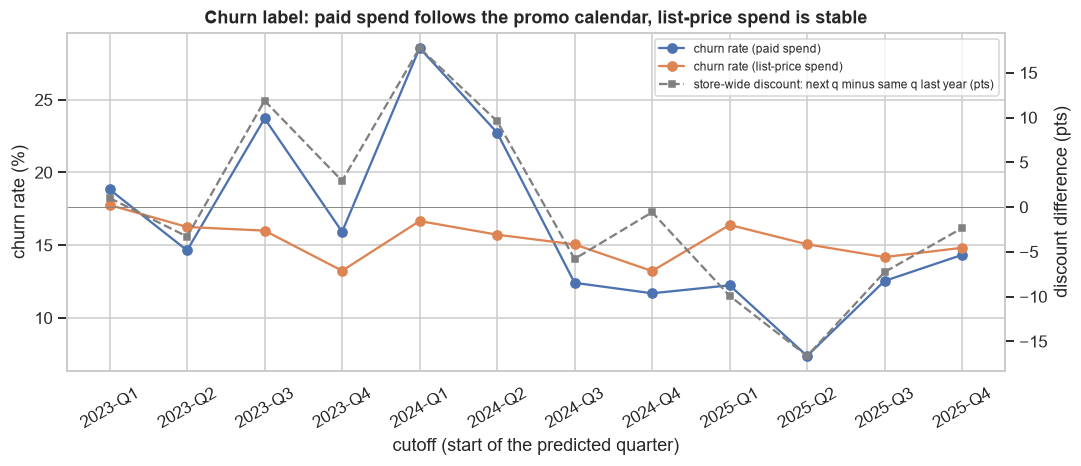

,churn rate (paid spend),churn rate (list-price spend),store-wide discount next q (%),store-wide discount same q last year (%)
cutoff,,,,
2023-01-01,0.188,0.178,1.011,0.000
2023-04-01,0.146,0.163,7.048,10.347
2023-07-01,0.237,0.160,13.049,1.174
2023-10-01,0.159,0.132,2.925,0.000
2024-01-01,0.286,0.167,18.777,1.011
2024-04-01,0.227,0.157,16.631,7.048
2024-07-01,0.124,0.150,7.261,13.049
2024-10-01,0.117,0.132,2.348,2.925
2025-01-01,0.122,0.164,8.860,18.777


In [3]:
def paid_spend(start, end):
    return con.sql(f"""SELECT customer_id, SUM(total_value) s FROM sales
                        WHERE date >= DATE '{start:%Y-%m-%d}' AND date < DATE '{end:%Y-%m-%d}' GROUP BY 1""").df().set_index('customer_id')['s']
q = pd.DateOffset(months=3)
promos = con.sql("SELECT start_date, end_date, discount_pct FROM promos WHERE target_type = 'All'").df()
def store_wide_discount(start, end):     # average store-wide discount % over the period
    days = pd.Series(0.0, index=pd.date_range(start, end - pd.Timedelta(days=1)))
    for r in promos.itertuples():
        days.loc[r.start_date:r.end_date] = np.maximum(days.loc[r.start_date:r.end_date], r.discount_pct)
    return days.mean()

rows = []
for c in cutoffs:
    nxt, ly = paid_spend(c, c + q), paid_spend(c - 4 * q, c - 3 * q)
    rows.append({'cutoff': c, 'churn rate (paid spend)': (nxt.reindex(ly.index).fillna(0) < DROP_RATIO * ly).mean(),
                 'churn rate (list-price spend)': data.loc[data['cutoff'] == c, 'churn'].mean(),
                 'store-wide discount next q (%)': store_wide_discount(c, c + q),
                 'store-wide discount same q last year (%)': store_wide_discount(c - 4 * q, c - 3 * q)})
labels = pd.DataFrame(rows).set_index('cutoff')

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(labels))
for col in labels.columns[:2]: ax.plot(x, labels[col] * 100, marker='o', label=col)
ax2 = ax.twinx(); ax2.plot(x, labels.iloc[:, 2] - labels.iloc[:, 3], color='grey', ls='--', marker='s', ms=4,
                           label='store-wide discount: next q minus same q last year (pts)')
ax2.axhline(0, color='grey', lw=.6); ax2.grid(False); ax2.set_ylabel('discount difference (pts)')
ax.set_xticks(x, [f'{c:%Y}-Q{c.quarter}' for c in labels.index], rotation=30)
ax.set_ylabel('churn rate (%)'); ax.set_xlabel('cutoff (start of the predicted quarter)'); ax.set_title('Churn label: paid spend follows the promo calendar, list-price spend is stable')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=8)
save('04a_churn_label'); plt.show()
labels

**Insights — choosing the label**
- With paid (after-discount) spend, the churn rate jumps between **7% and 29%** and follows the grey line: it peaks when the coming quarter has much deeper store-wide discounts than the same quarter last year (Q1 2024), and dips in the opposite case (Q2 2025). That label would teach the model the promo calendar, not customer behaviour.
- With list-price spend, the churn rate is steady at **13–18%** in every quarter. This is the label used from here on.
- About **1 in 7 customers** cuts spending by more than 30% in a given quarter, even though no one stops shopping.

## 2. Time-based split
| Split | Cutoffs | Outcome quarters | Used for |
|---|---|---|---|
| Train | Jan 2023 – Jan 2025 (9) | up to Mar 2025 | fitting the models |
| Validation | Apr 2025 | Apr–Jun 2025 | comparing models, choosing the decision threshold |
| Test | Oct 2025 | Oct–Dec 2025 | final accuracy, used once |

Every training outcome ends before the validation cutoff, and every validation outcome ends before the test cutoff, so no model ever sees the future.
The Jul 2025 cutoff is left out of evaluation (its outcome overlaps the gap) and is only used when refitting the final model.

In [4]:
train = data[data['cutoff'] <= '2025-01-01']
val   = data[data['cutoff'] == '2025-04-01']
test  = data[data['cutoff'] == '2025-10-01']
X = lambda d: d[CHURN_FEATURES]
pd.DataFrame({'rows': [len(train), len(val), len(test)],
              'churn rate': [train['churn'].mean(), val['churn'].mean(), test['churn'].mean()]},
             index=['train', 'validation', 'test'])

,rows,churn rate
train,90000,0.156
validation,10000,0.151
test,10000,0.148


## 3. Train three models and compare them on validation
Metrics: **ROC-AUC** (ranking quality), **PR-AUC** (precision-recall; more informative when churners are the minority),
**top-20% capture** (share of all churners found if marketing contacts the 20% highest-risk customers) and **Brier score** (probability accuracy, lower is better).

In [5]:
def top_capture(y, p, share=.2):
    top = np.argsort(-p)[:int(len(p) * share)]
    return y.to_numpy()[top].sum() / y.sum()

def evaluate(y, p):
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'top-20% capture': top_capture(y, p), 'Brier': brier_score_loss(y, p),
            'predicted rate': p.mean(), 'actual rate': y.mean()}

models = {
    'LogReg': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2000)),
    'RandomForest': make_pipeline(SimpleImputer(strategy='median'),
                                  RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42)),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', random_state=42),
}
val_scores = {}
for name, m in models.items():
    t = time.time(); m.fit(X(train), train['churn'])
    val_scores[name] = evaluate(val['churn'], m.predict_proba(X(val))[:, 1]) | {'fit_s': time.time() - t}
val_table = pd.DataFrame(val_scores).T
best_name = val_table['PR-AUC'].idxmax()
print('best on validation (PR-AUC):', best_name)
val_table

best on validation (PR-AUC): XGBoost


,ROC-AUC,PR-AUC,top-20% capture,Brier,predicted rate,actual rate,fit_s
LogReg,0.817,0.468,0.555,0.103,0.175,0.151,0.512
RandomForest,0.823,0.459,0.558,0.103,0.180,0.151,17.428
XGBoost,0.826,0.484,0.560,0.102,0.186,0.151,1.484


## 4. Final test (used once)
The decision threshold is chosen on **validation**: flag the 20% of customers with the highest predicted risk.
The same probability cut-off is then applied to the test quarter.

In [6]:
test_scores = {name: evaluate(test['churn'], m.predict_proba(X(test))[:, 1]) for name, m in models.items()}
display(pd.DataFrame(test_scores).T)

best = models[best_name]
p_val, p_test = best.predict_proba(X(val))[:, 1], best.predict_proba(X(test))[:, 1]
threshold = np.quantile(p_val, 0.8)
flag = (p_test >= threshold).astype(int)
cm = pd.DataFrame(confusion_matrix(test['churn'], flag), index=['actual: stayed', 'actual: churned'],
                  columns=['predicted: stay', 'predicted: churn'])
display(cm)
print(f'{best_name} at threshold {threshold:.3f}: flags {flag.mean():.0%} of customers | '
      f'precision {precision_score(test["churn"], flag):.2f} | recall {recall_score(test["churn"], flag):.2f} | '
      f'base churn rate {test["churn"].mean():.2f}')

,ROC-AUC,PR-AUC,top-20% capture,Brier,predicted rate,actual rate
LogReg,0.826,0.441,0.572,0.105,0.192,0.148
RandomForest,0.839,0.493,0.598,0.103,0.214,0.148
XGBoost,0.844,0.518,0.604,0.096,0.174,0.148


,predicted: stay,predicted: churn
actual: stayed,7605,913
actual: churned,660,822


XGBoost at threshold 0.327: flags 17% of customers | precision 0.47 | recall 0.55 | base churn rate 0.15


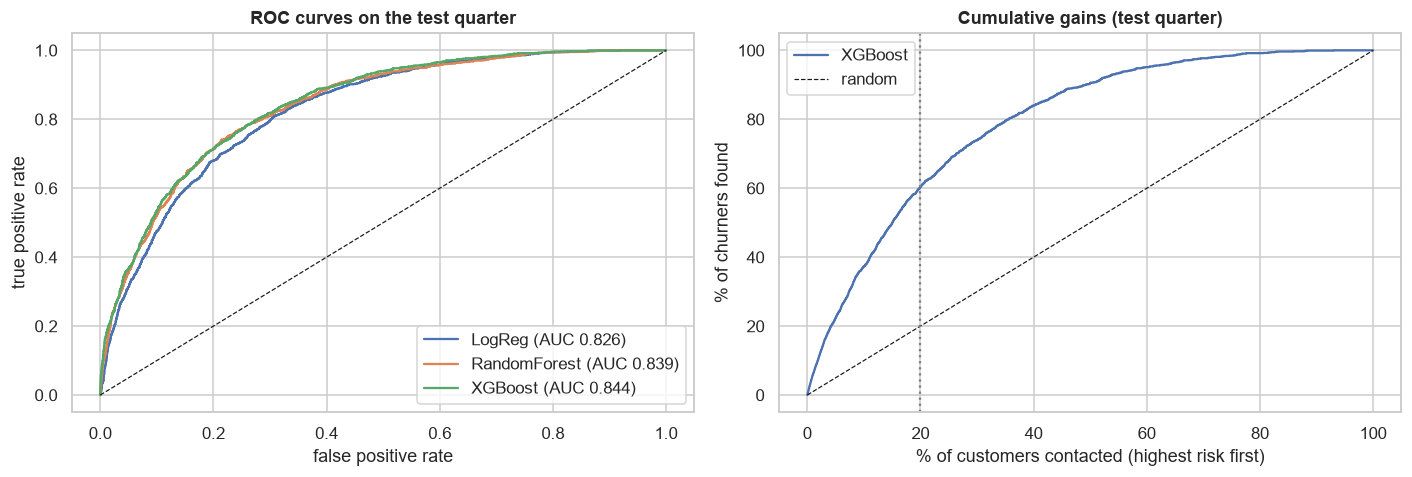

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, m in models.items():
    p = m.predict_proba(X(test))[:, 1]; fpr, tpr, _ = roc_curve(test['churn'], p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test['churn'], p):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_xlabel('false positive rate'); ax[0].set_ylabel('true positive rate')
ax[0].set_title('ROC curves on the test quarter'); ax[0].legend()

order = np.argsort(-p_test); y_sorted = test['churn'].to_numpy()[order]
share = np.arange(1, len(order) + 1) / len(order)
ax[1].plot(share * 100, np.cumsum(y_sorted) / y_sorted.sum() * 100, label=best_name)
ax[1].plot([0, 100], [0, 100], 'k--', lw=.8, label='random')
ax[1].axvline(20, color='grey', ls=':'); ax[1].set_xlabel('% of customers contacted (highest risk first)')
ax[1].set_ylabel('% of churners found'); ax[1].set_title('Cumulative gains (test quarter)'); ax[1].legend()
plt.tight_layout(); save('04b_roc_gains'); plt.show()

**Insights — model comparison and test**
- **XGBoost is best on validation and on test** (test ROC-AUC **0.844**, PR-AUC 0.52), within the guide's realistic range of 0.75–0.85. Random Forest is close, and even logistic regression reaches 0.83, so the signal is strong and simple rather than hidden in complex interactions.
- **For marketing:** contacting the 20% of customers with the highest predicted risk finds **60% of all churners**, 3× better than contacting customers at random.
- At the threshold chosen on validation, the model flags 17% of customers. Of those flagged, **47% really churn** (precision), versus 15% of all customers. It finds **55% of churners** (recall).
- The predicted churn rate on test (17%) is close to the actual 15%, so the probabilities are usable as well as the ranking.

**Robustness: is one test quarter enough?** Repeat the out-of-time test for five different quarters.
Each time the model is trained only on cutoffs whose outcome ends before the test cutoff.

In [8]:
rolling = []
for c in pd.date_range('2024-10-01', '2025-10-01', freq='QS'):
    tr = data[data['cutoff'] <= c - pd.DateOffset(months=6)]
    te = data[data['cutoff'] == c]
    m = XGBClassifier(**models['XGBoost'].get_params()).fit(X(tr), tr['churn'])
    rolling.append({'test quarter': f'{c:%Y-%m}', 'train cutoffs': tr['cutoff'].nunique()} | evaluate(te['churn'], m.predict_proba(X(te))[:, 1]))
pd.DataFrame(rolling).set_index('test quarter')

,train cutoffs,ROC-AUC,PR-AUC,top-20% capture,Brier,predicted rate,actual rate
test quarter,,,,,,,
2024-10,6,0.848,0.484,0.604,0.089,0.154,0.132
2025-01,7,0.829,0.508,0.558,0.107,0.182,0.164
2025-04,8,0.826,0.483,0.561,0.102,0.184,0.151
2025-07,9,0.835,0.472,0.579,0.099,0.188,0.142
2025-10,10,0.844,0.516,0.596,0.096,0.173,0.148


**Insights — robustness**
- Across five different test quarters, ROC-AUC stays between **0.83 and 0.85** and top-20% capture between 56% and 60%. The result is not a lucky quarter.
- The predicted churn rate is within 2–4 points of the actual rate each time. This is thanks to `target_quarter`: without it, the model over-predicted Q4 churn by about 2× in early tests.

## 5. What drives churn? (SHAP)

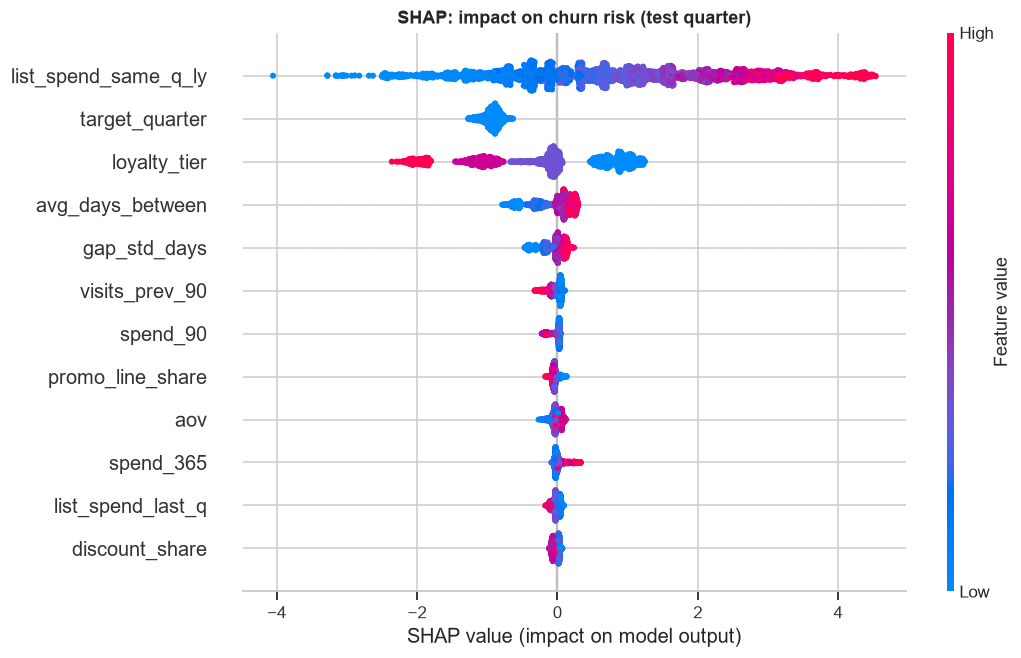

,mean |SHAP|
list_spend_same_q_ly,1.425
target_quarter,0.924
loyalty_tier,0.785
avg_days_between,0.212
gap_std_days,0.114
visits_prev_90,0.067
spend_90,0.054
promo_line_share,0.046
aov,0.046
spend_365,0.044


In [9]:
xgb = models['XGBoost']
sample = X(test).sample(3000, random_state=42)
sv = shap.TreeExplainer(xgb).shap_values(sample)
shap.summary_plot(sv, sample, max_display=12, show=False, plot_size=(10, 6))
plt.title('SHAP: impact on churn risk (test quarter)'); save('04c_churn_shap'); plt.show()
importance = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
importance.head(10).to_frame('mean |SHAP|')

In [10]:
# Churn rate by the two strongest drivers (test quarter)
t2 = test.assign(ly_quarter_band=pd.qcut(test['list_spend_same_q_ly'] / (test['spend_365'] / 4), 4,
                                         labels=['low', 'mid-low', 'mid-high', 'high']))
display(t2.groupby('loyalty_segment')['churn'].mean().loc[['Bronze', 'Silver', 'Gold', 'Platinum']].to_frame('churn rate'))
t2.groupby('ly_quarter_band', observed=True)['churn'].mean().to_frame('churn rate by last-year quarter vs own average')

,churn rate
loyalty_segment,
Bronze,0.197
Silver,0.154
Gold,0.092
Platinum,0.046


,churn rate by last-year quarter vs own average
ly_quarter_band,
low,0.028
mid-low,0.070
mid-high,0.156
high,0.339


**Insights — what drives churn (plain English)**
1. **A strong quarter last year makes a drop more likely.** The strongest driver is spend in the same quarter last year: when it was high compared with the customer's own average, a 30% drop is much more likely (34% churn in the top quarter of customers vs 3% in the bottom). Much of this "churn" is a return to normal after an unusually good quarter, not lost loyalty.
2. **Lower loyalty tiers churn more.** Bronze customers churn at 20% per quarter versus 5% for Platinum. Customers with fewer visits (`avg_days_between`, `gap_std_days`) have bumpier quarterly spend, so a 30% fall happens more easily.
3. **Season matters.** `target_quarter` sets a different baseline for each season (Q4, the test quarter, has lower risk). It is the same for every customer in a quarter, so it adjusts the overall level rather than the ranking.
4. **Recency barely matters.** Days since last visit and the overdue ratio are not among the top drivers. A short gap in visits does not predict a drop in spend in this data.

## 6. Score today's customers
The final model is refit on **all** cutoffs with a known outcome (Jan 2023 – Oct 2025), using the settings chosen above,
and applied to features at **1 January 2026** to predict Q1 2026. Probabilities are grouped into risk bands.

In [11]:
final = XGBClassifier(**models['XGBoost'].get_params()).fit(X(data), data['churn'])
now = pd.Timestamp('2026-01-01')
today = churn_table(con, now, with_label=False)
today['churn_prob'] = final.predict_proba(X(today))[:, 1]
today['risk_band'] = pd.cut(today['churn_prob'], [0, 0.4, 0.7, 1.0], labels=['Low', 'Medium', 'High'], include_lowest=True)

seg = pd.read_csv(PROC / 'customer_segments.csv', index_col='customer_id')['Segment']
today = today.join(seg)
print(f"predicted churn rate for Q1 2026: {today['churn_prob'].mean():.1%}")
bands = today.groupby('risk_band', observed=True).agg(customers=('churn_prob', 'size'), avg_prob=('churn_prob', 'mean'),
                                                       last_year_spend=('spend_365', 'sum'))
bands['share_%'] = bands['customers'] / len(today) * 100
bands['share_of_revenue_%'] = bands['last_year_spend'] / today['spend_365'].sum() * 100
bands   # revenue at risk = last-year spend of the High (and Medium) band

predicted churn rate for Q1 2026: 20.4%


,customers,avg_prob,last_year_spend,share_%,share_of_revenue_%
risk_band,,,,,
Low,8294,0.133,"2,530,421,429.470",82.940,84.043
Medium,1463,0.514,"414,156,168.830",14.630,13.755
High,243,0.784,"66,304,709.190",2.430,2.202


,customers,avg_churn_prob,high_risk,medium_risk
Segment,,,,
Champions,1020,0.114,0,81
Loyal,1889,0.153,25,152
Regulars,2377,0.206,48,344
Occasional,2397,0.254,88,477
Slipping Away,2317,0.232,82,409


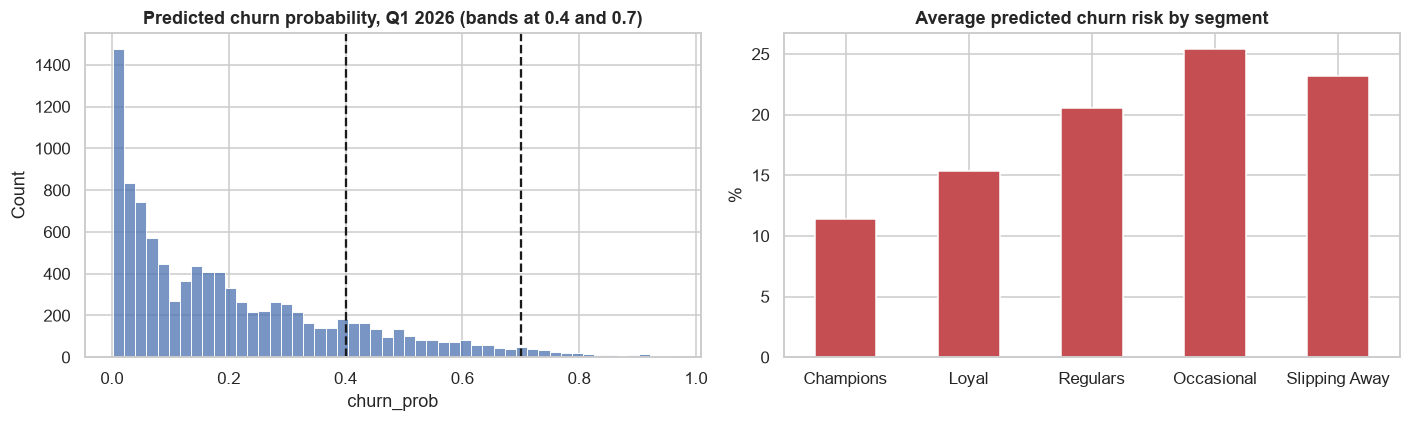

In [12]:
order = ['Champions', 'Loyal', 'Regulars', 'Occasional', 'Slipping Away']
by_seg = today.groupby('Segment').agg(customers=('churn_prob', 'size'), avg_churn_prob=('churn_prob', 'mean'),
                                      high_risk=('risk_band', lambda s: (s == 'High').sum()),
                                      medium_risk=('risk_band', lambda s: (s == 'Medium').sum())).loc[order]
display(by_seg)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(today['churn_prob'], bins=50, ax=ax[0]); ax[0].axvline(.4, color='k', ls='--'); ax[0].axvline(.7, color='k', ls='--')
ax[0].set_title('Predicted churn probability, Q1 2026 (bands at 0.4 and 0.7)')
by_seg['avg_churn_prob'].mul(100).plot.bar(ax=ax[1], rot=0, color='C3'); ax[1].set_ylabel('%'); ax[1].set_xlabel('')
ax[1].set_title('Average predicted churn risk by segment')
plt.tight_layout(); save('04d_churn_today'); plt.show()

In [13]:
first_calls = today[(today['risk_band'] != 'Low') & (today['Segment'].isin(['Champions', 'Loyal']))] \
                .sort_values('churn_prob', ascending=False)
print(f'{len(first_calls)} medium/high-risk Champions or Loyal customers -- the first people to contact')
first_calls[['Segment', 'loyalty_segment', 'churn_prob', 'risk_band', 'spend_365']].head(10)

258 medium/high-risk Champions or Loyal customers -- the first people to contact


,Segment,loyalty_segment,churn_prob,risk_band,spend_365
customer_id,,,,,
CUST05928,Loyal,Gold,0.905,High,"453,764.430"
CUST04154,Loyal,Gold,0.904,High,"503,276.610"
CUST02783,Loyal,Gold,0.881,High,"538,539.790"
CUST09234,Loyal,Gold,0.850,High,"503,395.750"
CUST01312,Loyal,Gold,0.800,High,"483,277.830"
CUST09447,Loyal,Gold,0.755,High,"517,587.890"
CUST06644,Loyal,Gold,0.748,High,"502,925.550"
CUST03300,Loyal,Gold,0.743,High,"567,000.340"
CUST01667,Loyal,Gold,0.740,High,"503,976.500"


In [14]:
out = today[['churn_prob', 'risk_band', 'Segment', 'loyalty_segment', 'spend_365', 'recency_days', 'avg_days_between']]
out.to_csv(PROC / 'customer_churn.csv', index_label='customer_id', float_format=FLOAT)
joblib.dump({'model': final, 'features': CHURN_FEATURES, 'drop_ratio': DROP_RATIO, 'threshold_top20': threshold},
            MODELS / 'churn_xgb.pkl')
print('saved customer_churn.csv', out.shape, 'and models/churn_xgb.pkl')

saved customer_churn.csv (10000, 7) and models/churn_xgb.pkl


**Insights — today's customers (Q1 2026)**
- **243 customers (2.4%) are High risk** (probability > 0.7) and 1,463 (14.6%) are Medium risk. High-risk customers account for ~2% of last year's revenue, and Medium-risk ones for ~14%.
- The model predicts a 20% churn rate for Q1 2026, a little above past Q1 quarters (16–18%). Use the ranking and the bands to decide who to contact, rather than treating 20% as a firm forecast.
- **By segment:** risk is highest for *Occasional* (25%) and *Slipping Away* (23%) customers and lowest for *Champions* (11%). *Slipping Away* is **not** riskier than *Occasional*, which confirms that a recent gap in visits is a weak churn signal (Step 3 left this open).
- **First calls:** 258 Medium/High-risk *Champions* or *Loyal* customers (mostly Gold). Each spends ~PKR 0.5M a year, so keeping them matters most.

**Why this setup has no leakage**
Features are built only from sales **before** each cutoff date, and the churn label comes only from the 3 months **after** it. Recency is allowed as a feature because it is measured at the cutoff, while the label looks forward. Models are trained on earlier quarters and tested on later, unseen quarters, with a gap so that no training outcome overlaps the test period. The decision threshold was chosen on a separate validation quarter, and the test quarter was used once. The result, ROC-AUC ≈ 0.84 and stable across five quarters, is in the range the guide expects for an honest model; an AUC near 1.0 would have signalled leakage.

**Done-when check (Step 4)**
- ✅ Model comparison table (validation and test) and ROC + cumulative-gains charts (`reports/figures/04b_roc_gains.png`)
- ✅ SHAP chart (`reports/figures/04c_churn_shap.png`) and plain-English drivers
- ✅ Risk bands for today's customers → `data/processed/customer_churn.csv`; model → `models/churn_xgb.pkl`
- ✅ Business view by segment and the list of first customers to contact
- ✅ Leakage explanation (above)

**Carry forward:** Step 7 tunes this model with Optuna and tracks it in MLflow; the dashboard (Step 8) reads `customer_churn.csv`.